# UCS420: Cognitive Computing 
## Matplotlib and Seaborn

**Name:** Waris
**Roll Number:** 1024170155


In [21]:
import sys
print(sys.executable)

/Users/waris/Downloads/pk/.venv/bin/python


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


## Q1: Plotting M·x² and M·sin(x)\nAsk the user for a value M, generate x from -10 to 10, and plot both functions together.

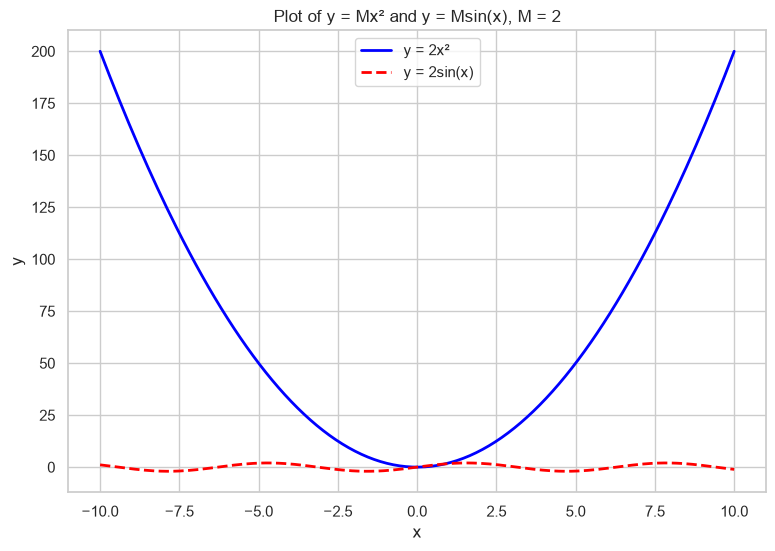

In [23]:
M = 2

x = np.linspace(-10, 10, 200)

y_quad = M * x**2
y_sin = M * np.sin(x)

plt.figure(figsize=(9, 6))

plt.plot(
    x, y_quad,
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"y = {M}x²"
)

plt.plot(
    x, y_sin,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"y = {M}sin(x)"
)

plt.title(f"Plot of y = Mx² and y = Msin(x), M = {M}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## Q2: Seaborn Bar Plot of Subject Scores

In [24]:
waris_data = {
    "Subject": ["Maths", "Physics", "Chemistry", "English", "Computer Science"],
    "Score": [85, 78, 92, 74, 96]
}
scores_df = pd.DataFrame(waris_data)
scores_df


,Subject,Score
0,Maths,85
1,Physics,78
2,Chemistry,92
3,English,74
4,Computer Science,96


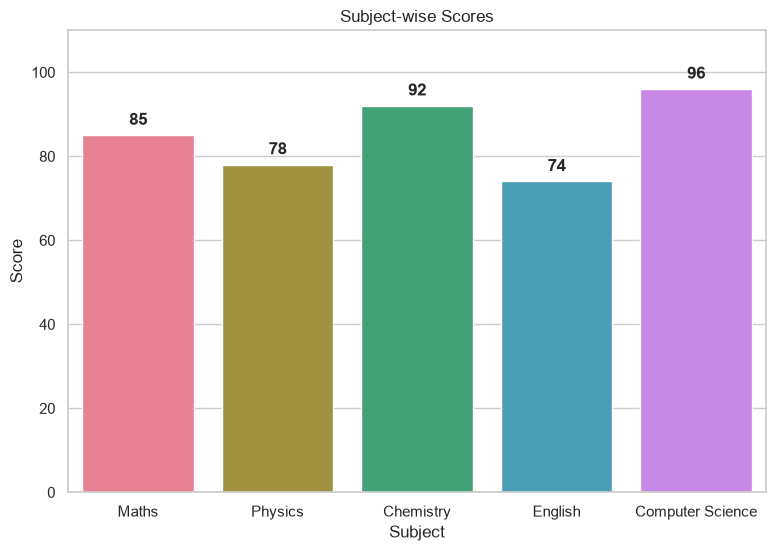

In [25]:
plt.figure(figsize=(9, 6))
palette = sns.color_palette("husl", len(scores_df))
ax = sns.barplot(data=scores_df, x="Subject", y="Score", hue="Subject",
                  palette=palette, legend=False)

# Annotate each bar with its score value
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(f"{height:.0f}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha="center", va="bottom", fontweight="bold")

plt.title("Subject-wise Scores")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.ylim(0, 110)
plt.grid(True, axis="y")
plt.show()


## Q3: Random Data with Roll Number Seed — Cumulative Sum and Scatter Plots\nRoll number **1024170155** is used as the NumPy random seed.

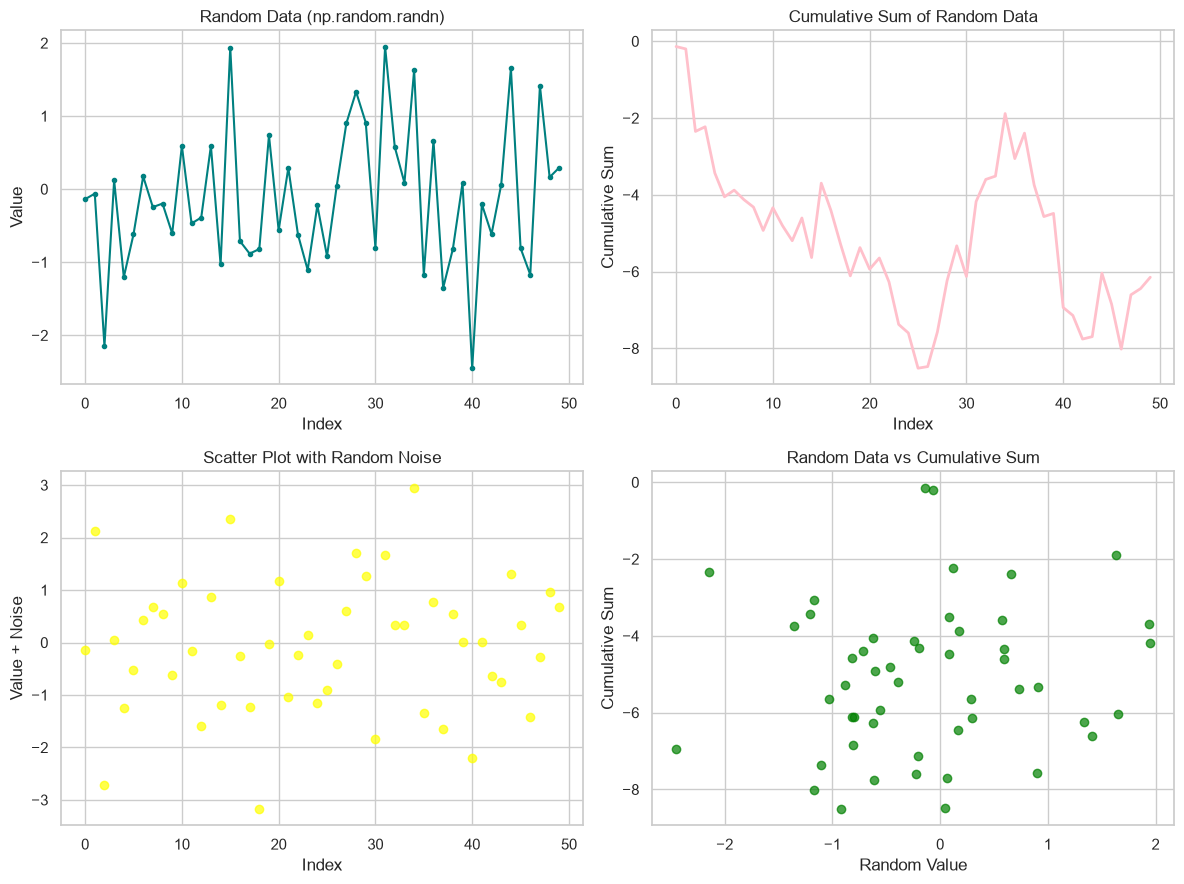

In [26]:
roll_number = 1024170155
np.random.seed(roll_number)

data_50 = np.random.randn(50)
cumulative_sum = np.cumsum(data_50)
noise = np.random.randn(50)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Top-left: Line plot of the raw random data
axes[0, 0].plot(data_50, color="teal", marker="o", markersize=3)
axes[0, 0].set_title("Random Data (np.random.randn)")
axes[0, 0].set_xlabel("Index")
axes[0, 0].set_ylabel("Value")
axes[0, 0].grid(True)

# Top-right: Line plot showing cumulative sum
axes[0, 1].plot(cumulative_sum, color="pink", linewidth=2)
axes[0, 1].set_title("Cumulative Sum of Random Data")
axes[0, 1].set_xlabel("Index")
axes[0, 1].set_ylabel("Cumulative Sum")
axes[0, 1].grid(True)

# Bottom-left: Scatter plot with random noise
axes[1, 0].scatter(np.arange(50), data_50 + noise, color="yellow", alpha=0.7)
axes[1, 0].set_title("Scatter Plot with Random Noise")
axes[1, 0].set_xlabel("Index")
axes[1, 0].set_ylabel("Value + Noise")
axes[1, 0].grid(True)

# Bottom-right: Scatter of data vs cumulative sum
axes[1, 1].scatter(data_50, cumulative_sum, color="green", alpha=0.7)
axes[1, 1].set_title("Random Data vs Cumulative Sum")
axes[1, 1].set_xlabel("Random Value")
axes[1, 1].set_ylabel("Cumulative Sum")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


## Q4: Company Sales Data Analysis\nDataset: [company_sales_data.csv](https://github.com/AnjulaMehto/MCA/blob/main/company_sales_data.csv)

In [27]:
sales_df = pd.read_csv("company_sales_data.csv")
sales_df


,month_number,facecream,facewash,toothpaste,bathingsoap,shampoo,moisturizer,total_units,total_profit
0,1,2500,1500,5200,9200,1200,1500,21100,211000
1,2,2630,1200,5100,6100,2100,1200,18330,183300
2,3,2140,1340,4550,9550,3550,1340,22470,224700
3,4,3400,1130,5870,8870,1870,1130,22270,222700
4,5,3600,1740,4560,7760,1560,1740,20960,209600
5,6,2760,1555,4890,7490,1890,1555,20140,201400
6,7,2980,1120,4780,8980,1780,1120,29550,295500
7,8,3700,1400,5860,9960,2860,1400,36140,361400
8,9,3540,1780,6100,8100,2100,1780,23400,234000
9,10,1990,1890,8300,10300,2300,1890,26670,266700


### 1. Total profit of all months — Line plot

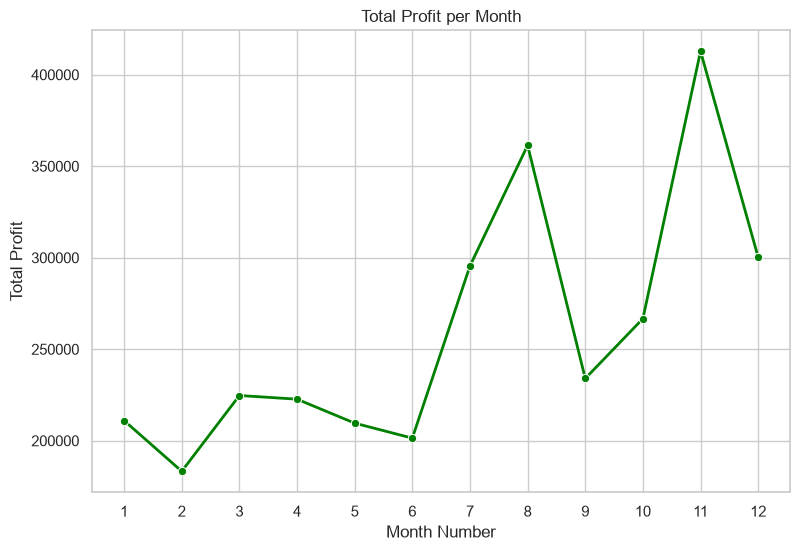

In [28]:
plt.figure(figsize=(9, 6))
sns.lineplot(data=sales_df, x="month_number", y="total_profit",
             marker="o", color="green", linewidth=2)

plt.title("Total Profit per Month")
plt.xlabel("Month Number")
plt.ylabel("Total Profit")
plt.xticks(sales_df["month_number"])
plt.grid(True)
plt.show()


### 2. All product sales data — Multiline plot

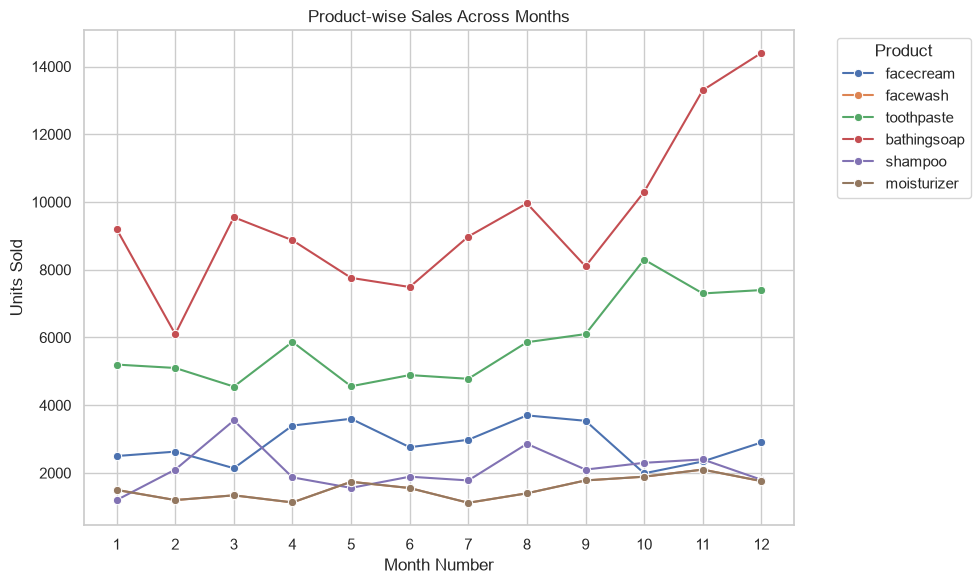

In [29]:
product_cols = ["facecream", "facewash", "toothpaste", "bathingsoap", "shampoo", "moisturizer"]

sales_melted = sales_df.melt(id_vars="month_number", value_vars=product_cols,
                              var_name="Product", value_name="Units Sold")

plt.figure(figsize=(10, 6))
sns.lineplot(data=sales_melted, x="month_number", y="Units Sold",
             hue="Product", marker="o")

plt.title("Product-wise Sales Across Months")
plt.xlabel("Month Number")
plt.ylabel("Units Sold")
plt.xticks(sales_df["month_number"])
plt.legend(title="Product", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


### 3. Bar chart for all features/attributes

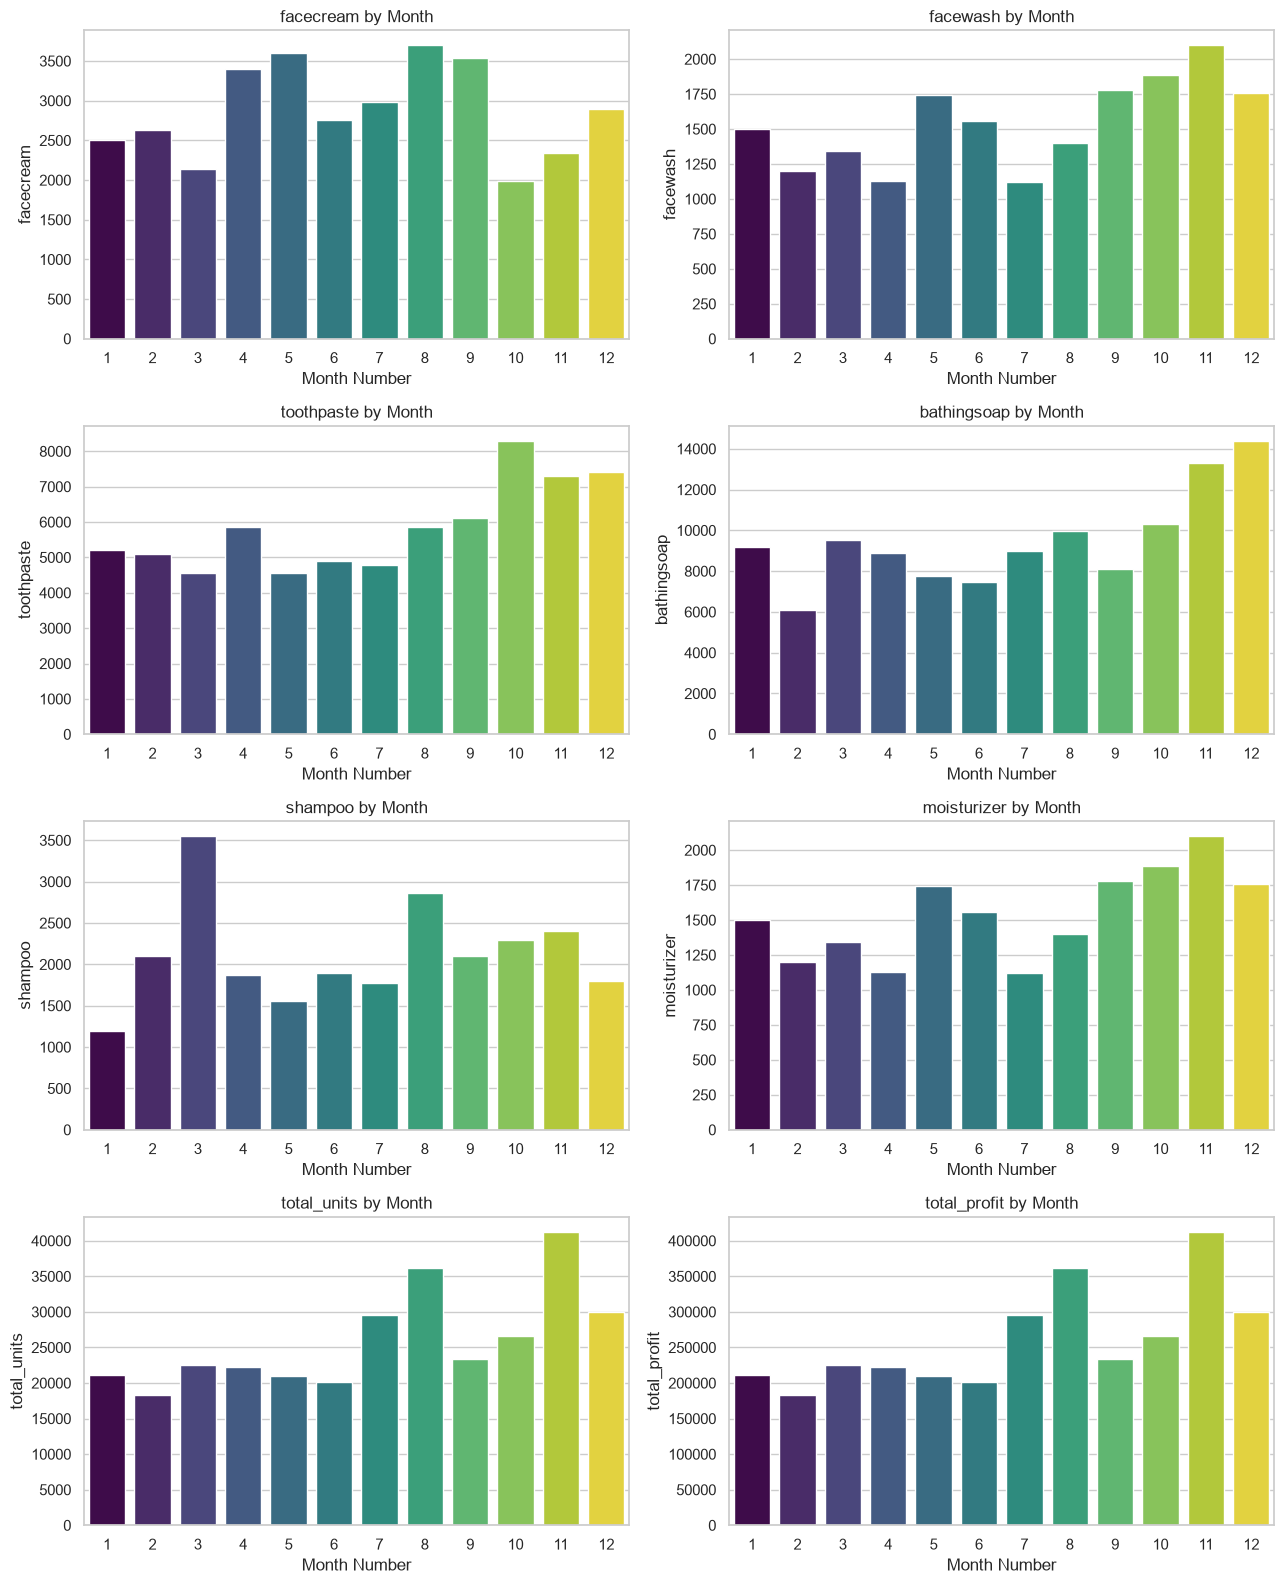

In [30]:
all_feature_cols = ["facecream", "facewash", "toothpaste", "bathingsoap",
                     "shampoo", "moisturizer", "total_units", "total_profit"]

fig, axes = plt.subplots(4, 2, figsize=(13, 16))
axes = axes.flatten()

for i, col in enumerate(all_feature_cols):
    sns.barplot(data=sales_df, x="month_number", y=col, hue="month_number",
                palette="viridis", legend=False, ax=axes[i])
    axes[i].set_title(f"{col} by Month")
    axes[i].set_xlabel("Month Number")
    axes[i].set_ylabel(col)
    axes[i].grid(True, axis="y")

plt.tight_layout()
plt.show()
